# M3 Assignment Solution

**Kapil Kumar Sharma**

**NET ID: apl25002**

**Date: 26-09-2026**

# Environment Setup

In [123]:
# import modules

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

!pip install scikit-learn
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from pandas.plotting import parallel_coordinates
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


# Set display options to show all columns
pd.set_option('display.max_columns', None)


# Question 1. Read in the dataset and determine how many rows and columns it has.


In [124]:
# read the dataset file. File reading failed due to error in data encoding, so encoding method changed.
df = pd.read_csv('spotify-2023.csv', encoding="latin1")

In [125]:
# shape
df.shape

# Number of rows
print("Number of rows:", df.shape[0])

# Number of columns
print("Number of columns:", df.shape[1])

Number of rows: 953
Number of columns: 25


In [126]:
# Preview
df.head()

,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,streams (M),in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,141.381703,43,263,45,10,826,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,133.716286,48,126,58,14,382,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,140.003974,94,207,91,14,949,138,F,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,800.840817,116,207,125,12,548,170,A,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,303.236322,84,133,87,15,425,144,A,Minor,65,23,80,14,63,11,6


# Comment 1: Dataset read from spotify-2023 csv file. And Number of rows is 953 and column is 25.

# Question 2. The target variable for this dataset is the streams (M) column.  Check the datatype of streams.  If it isn’t already int64, update it.  Hint: if needed, drop a row of problematic data to get it to convert properly.


In [127]:
print("Data type:", df['streams (M)'].dtype)
print(df['streams (M)'].head())

Data type: object
0    141.381703
1    133.716286
2    140.003974
3    800.840817
4    303.236322
Name: streams (M), dtype: object


Comment: Data have . (dots) in it. Convert to float than to int would be the approach.

In [128]:
# Try to convert it to int64
df['streams (M)'] = df['streams (M)'].astype(float).astype(int)

ValueError: could not convert string to float: 'BPM110KeyAModeMajorDanceability53Valence75Energy69Acousticness7Instrumentalness0Liveness17Speechiness3'

Comment: Failed due to data error. As mentioned in instructions, remove/drop the row with string data.

In [129]:
df[df['streams (M)'].astype(str) == 'BPM110KeyAModeMajorDanceability53Valence75Energy69Acousticness7Instrumentalness0Liveness17Speechiness3']

,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,streams (M),in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
574,Love Grows (Where My Rosemary Goes),Edison Lighthouse,1,1970,1,1,2877,0,BPM110KeyAModeMajorDanceability53Valence75Ener...,BPM110KeyAModeMajorDanceability53Valence75Ener...,16,0,54,0,0,110,A,Major,53,75,69,7,0,17,3


In [130]:
df = df.drop(574)

In [131]:
df['streams (M)'] = df['streams (M)'].astype(float).astype(int)

Comment: Column 'streams (M)' converted to int type.

In [132]:
print("Data type:", df['streams (M)'].dtype)
print(df['streams (M)'].head())

Data type: int64
0    141
1    133
2    140
3    800
4    303
Name: streams (M), dtype: int64


# Comment 2: Datatype of streams (M) is now int64.

# Question 3. Perform hierarchical clustering on danceability_%, valence_%, energy_%, acousticness_%, instrumentalness_%, liveliness_%, and speechiness_%.


a. How many clusters are you keeping and why?  Justify your response with the dendrogram and the merge distance line chart.


b. Produce the parallel plot for the cluster means.  Describe the notable attributes of each cluster and give each cluster a meaningful name.


c. Produce row level parallel plots for each cluster and the biplot of the clusters.  Describe the observable variability within the clusters and between the clusters.

In [133]:
# Check datatype for all the clustring variables.
cluster_cols = [
    'danceability_%',
    'valence_%',
    'energy_%',
    'acousticness_%',
    'instrumentalness_%',
    'liveness_%',
    'speechiness_%'
]

for col in cluster_cols:
    print(col, ":", df[col].dtype)

danceability_% : int64
valence_% : int64
energy_% : int64
acousticness_% : int64
instrumentalness_% : int64
liveness_% : int64
speechiness_% : int64


Comment: All cluster variables are continous variable, so good to go further for hierracial clustering.

In [134]:
# Select the columns for clustering.
df_clustering = df[cluster_cols]

# Standardize the data.
# It's important to standardize features before hierarchical clustering
# as distance metrics are sensitive to scale.
scaler = StandardScaler()
df_scaled_clustering = scaler.fit_transform(df_clustering)

# Convert the scaled data back to a pandas DataFrame for easier handling (optional but good practice)
# Use the original column names
df_scaled_clustering = pd.DataFrame(df_scaled_clustering, columns=cluster_cols)

# Print the first few rows of the dataframe to verify that the data is standardized
print(df_scaled_clustering.head())

   danceability_%  valence_%  energy_%  acousticness_%  instrumentalness_%  \
0        0.890052   1.601891  1.131483        0.150886           -0.188234   
1        0.274608   0.408787  0.587671       -0.772619           -0.188234   
2       -1.093045  -0.826928 -0.681226       -0.387825           -0.188234   
3       -0.819514   0.280954  0.466823       -0.618702           -0.188234   
4       -0.135688  -1.210426  0.950212       -0.503264            7.303165   

   liveness_%  speechiness_%  
0   -0.744961      -0.619429  
1   -0.599095      -0.619429  
2    0.932504      -0.417616  
3   -0.526161       0.490540  
4   -0.526161      -0.417616  


Data is standardized.

We will be using 'Ward' method, which is common. It consider loss of information when observations are clustered together. Uses error sum of squares (ESS) to measure difference between observations and the centroid.

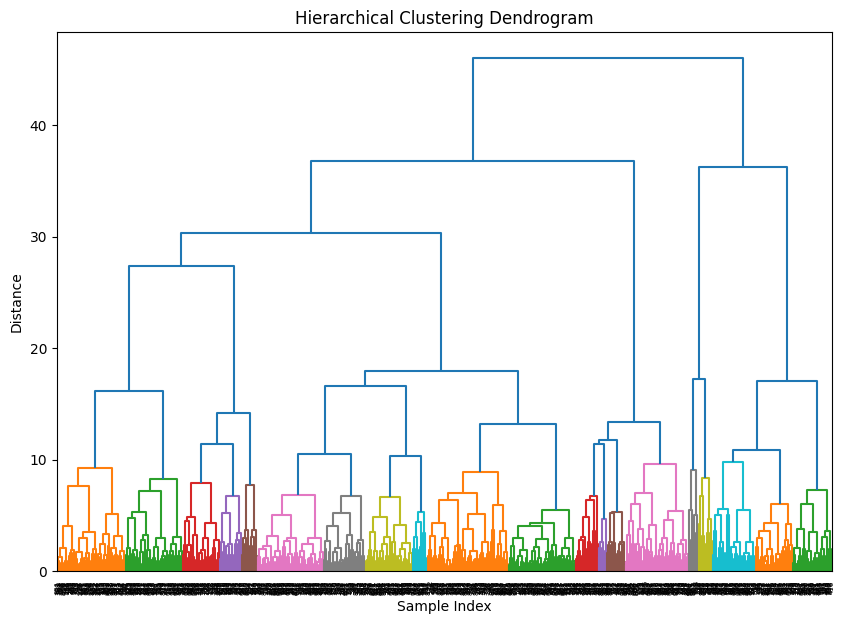

In [135]:
# Perform hierarchical clustering
linked = linkage(df_scaled_clustering, 'ward')

# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True,
           color_threshold=10) # optional color_threshold

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

The dendrogram shows the order in which the the rows were combined into clusters.  

Each horizontal line indicates a join that happened.  The height of the horizontal line (as measured by the y axis) shows the distance between the two subgroups that were combined to form that join.  

I hard coded the color_threshold to 10 so that the dendrogram would show nine color coded clusters which matches what we choose later on in the code.

It can be helpful to also look at the numbers so let's make a table of all the distances from which the dendrogram is formed.  

In [136]:
# Print the distances used to generate the dendrogram
# The third column of the linkage matrix contains the distances at which merges occur.
distances = linked[:, 2]

# The linkage matrix 'linked' has shape (n-1, 4), where n is the number of original observations.
# Each row represents a merge. The third column (index 2) is the distance of the merge.
# The last column (index 3) is the number of original observations in the new cluster.

# We can sort the distances to see the order of merges
sorted_distances = np.sort(distances)
# print("\nSorted distances at which merges occurred:")
# print(sorted_distances)

# Let's create a DataFrame to show the distances and the number of clusters that would exist
# if we cut the dendrogram at that distance (approximately).
# The number of clusters starts at the number of data points (951) and decreases by 1 at each merge.
num_original_points = df_scaled_clustering.shape[0]
num_clusters_at_merge = np.arange(num_original_points - 1, 0, -1)

# Create a DataFrame with distances and corresponding number of clusters
distances_df = pd.DataFrame({
    'Merge Distance': sorted_distances,
    'Number of Clusters After Merge': num_clusters_at_merge
})

# Print the DataFrame
print("\nMerge Distances and Corresponding Number of Clusters:")
display(distances_df)

# Lets examine this table and the dendrogram to help decide on a suitable number of clusters
# by looking for large jumps in the merge distance.


Merge Distances and Corresponding Number of Clusters:


,Merge Distance,Number of Clusters After Merge
0,0.000000,951
1,0.109534,950
2,0.121894,949
3,0.171729,948
4,0.179022,947
...,...,...
946,27.365854,5
947,30.300160,4
948,36.242580,3
949,36.810998,2


Note that the distances increase as the the number of clusters decrease.  

That's because each subsequent join brings together groups that are a little more different than the previous join.

In the beginning we are combining rows that are very similar with very small, nearly zero deistances.  By the end we are joining clusters with distances of 3, 6, or more.

A picture of the distances can help us pick the optimal number of clusters.

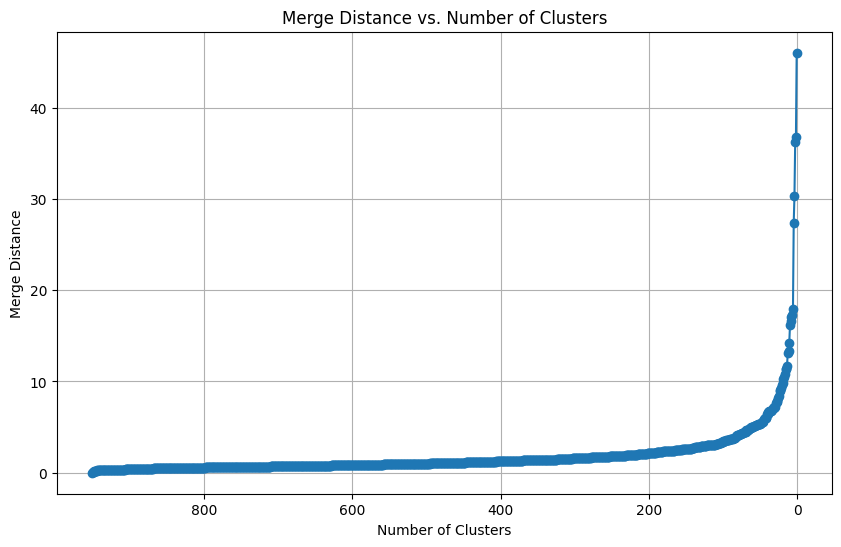

In [137]:
# Plot the distance and number of clusters
plt.figure(figsize=(10, 6))
plt.plot(distances_df['Number of Clusters After Merge'], distances_df['Merge Distance'], marker='o', linestyle='-')
plt.title('Merge Distance vs. Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Merge Distance')
plt.grid(True)
plt.gca().invert_xaxis() # Invert x-axis so 1 cluster is on the right
plt.show()

Here we have a plot of merge distance by the number of clusters, descending.  As the number of clusters decreases, we are forced to combine groups of rows that are increasingly different.  

When interpreting this type of plot, we look for an elbow in the line which shows a big jump in how different things are.  

In this plot, 6 clusters stands out to me as an important point.  See how there are several joins with a distance of 15 to 18 and then it jumps up to 28?

Admittedly, this is a bit of a judgement call that also relies on the business situation.

Now let's save the cluster numbers for each row for 6 clusters.  We will do this for both the original data and the standardized data.  

In [138]:
# Get the cluster assignments for k=5
k = 6
clusters = fcluster(linked, t=k, criterion='maxclust')

# Assign the cluster labels to the dataframe
df['Cluster'] = clusters

# Print the first few rows of the dataframe to verify that the cluster labels have been assigned
print(df.head())

                            track_name    artist(s)_name  artist_count  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook             2   
1                                 LALA       Myke Towers             1   
2                              vampire    Olivia Rodrigo             1   
3                         Cruel Summer      Taylor Swift             1   
4                       WHERE SHE GOES         Bad Bunny             1   

   released_year  released_month  released_day  in_spotify_playlists  \
0           2023               7            14                   553   
1           2023               3            23                  1474   
2           2023               6            30                  1397   
3           2019               8            23                  7858   
4           2023               5            18                  3133   

   in_spotify_charts    streams  streams (M)  in_apple_playlists  \
0                147  141381703          141          

In [139]:
# Assign the cluster labels to the standardized dataframe
df_scaled_clustering['Cluster'] = clusters

# Print the first few rows of the dataframe to verify that the standardized data has the clusters added too
print(df_scaled_clustering.head())

   danceability_%  valence_%  energy_%  acousticness_%  instrumentalness_%  \
0        0.890052   1.601891  1.131483        0.150886           -0.188234   
1        0.274608   0.408787  0.587671       -0.772619           -0.188234   
2       -1.093045  -0.826928 -0.681226       -0.387825           -0.188234   
3       -0.819514   0.280954  0.466823       -0.618702           -0.188234   
4       -0.135688  -1.210426  0.950212       -0.503264            7.303165   

   liveness_%  speechiness_%  Cluster  
0   -0.744961      -0.619429        4  
1   -0.599095      -0.619429        4  
2    0.932504      -0.417616        4  
3   -0.526161       0.490540        4  
4   -0.526161      -0.417616        2  


# Comment 3.a) We will be keeping 6 clusters. From dendrogram and the merge distance line chart, 6 clusters stands out to me as an important point.

Regarding b. Produce the parallel plot for the cluster means.  Describe the notable attributes of each cluster and give each cluster a meaningful name.


Mean of Scaled Variables per Cluster:
         danceability_%  valence_%  energy_%  acousticness_%  \
Cluster                                                        
1             -0.758109  -0.501405 -1.310536        1.612318   
2             -0.529477  -0.904803 -0.418695        0.282247   
3              0.412849   0.020078 -0.058297       -0.019088   
4              0.365552   0.675786  0.560781       -0.370505   
5             -0.426502  -0.133448  0.274928       -0.165829   
6             -0.223923  -0.999571 -0.202515       -0.532806   

         instrumentalness_%  liveness_%  speechiness_%  
Cluster                                                 
1                 -0.114623   -0.256259      -0.461548  
2                  4.818333   -0.236943      -0.490686  
3                 -0.179680   -0.344091       1.996148  
4                 -0.143833   -0.104417      -0.308968  
5                 -0.184314    2.001657      -0.256831  
6                 -0.160616   -0.315831      -0.3

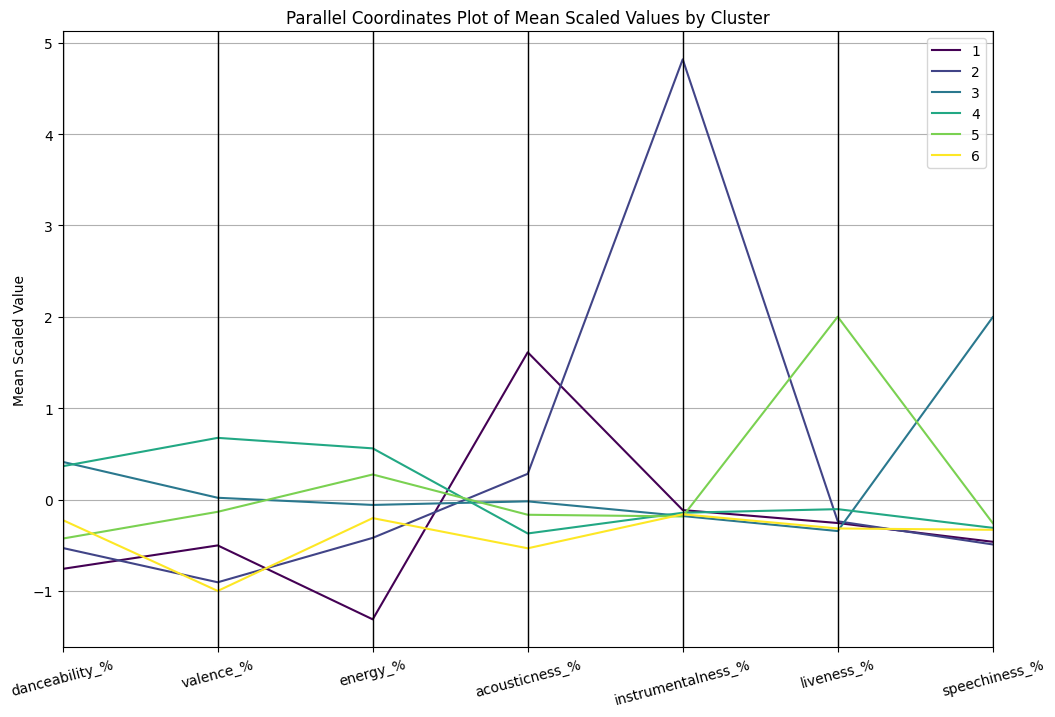

In [140]:
# Parallel Coordinates Plot
# The parallel coordinates plot is useful for visualizing the values of each variable
# for records belonging to different clusters. It helps see the profile of each cluster.
# It's best used with scaled data.

# Select the columns to plot (all numeric columns except 'Cluster')
cols_for_plotting = cluster_cols + ['Cluster'] # Include the Cluster column for coloring
df_plot = df_scaled_clustering[cols_for_plotting]

# To get a better sense of the cluster profiles, we can calculate the mean
# of the scaled variables for each cluster.
cluster_means_scaled = df_scaled_clustering.groupby('Cluster')[cluster_cols].mean()

print("\nMean of Scaled Variables per Cluster:")
print(cluster_means_scaled)

# Add cluster counts
cluster_counts = df_scaled_clustering['Cluster'].value_counts().sort_index()
print("\nNumber of Data Points per Cluster:")
print(cluster_counts)

# We can visualize these means on a parallel coordinates plot
plt.figure(figsize=(12, 8))
parallel_coordinates(cluster_means_scaled.reset_index(), 'Cluster', colormap=plt.get_cmap("viridis")) # Use reset_index() to make Cluster a column again

plt.title('Parallel Coordinates Plot of Mean Scaled Values by Cluster')
plt.ylabel('Mean Scaled Value')
plt.xticks(rotation=15)
plt.grid(True)
plt.show()

Data dictionary defination for cluster columns:

danceability_%: Suitability of the song for dancing. & valence_%: Positivity of the song’s musical content.

energy_%: Perceived energy level of the song. & acousticness_%: Acoustic sound presence in the song.

instrumentalness_%: Proportion of instrumental content in the track. &
liveness_%: Presence of live performance elements.

speechiness_%: Amount of spoken words in the song.


# Comment 3.b) From this, we can make observations about the clusters.  Cluster 4 is the biggest with 391 songs (almost 40% of data) and they are the songs that are most suitable for dancing with average musical content and very common speechiness. Cluster 1 have second most largest songs of 147 songs group. From the chart danceability, valence, energy were low or average but the presence of acoustic sound is high. Cluster 2 occurs the least frequently with only 29 songs in this group. These songs have low danceability, energy but highest instrumental content in the track.

Regarding c. Produce row level parallel plots for each cluster and the biplot of the clusters.  Describe the observable variability within the clusters and between the clusters.

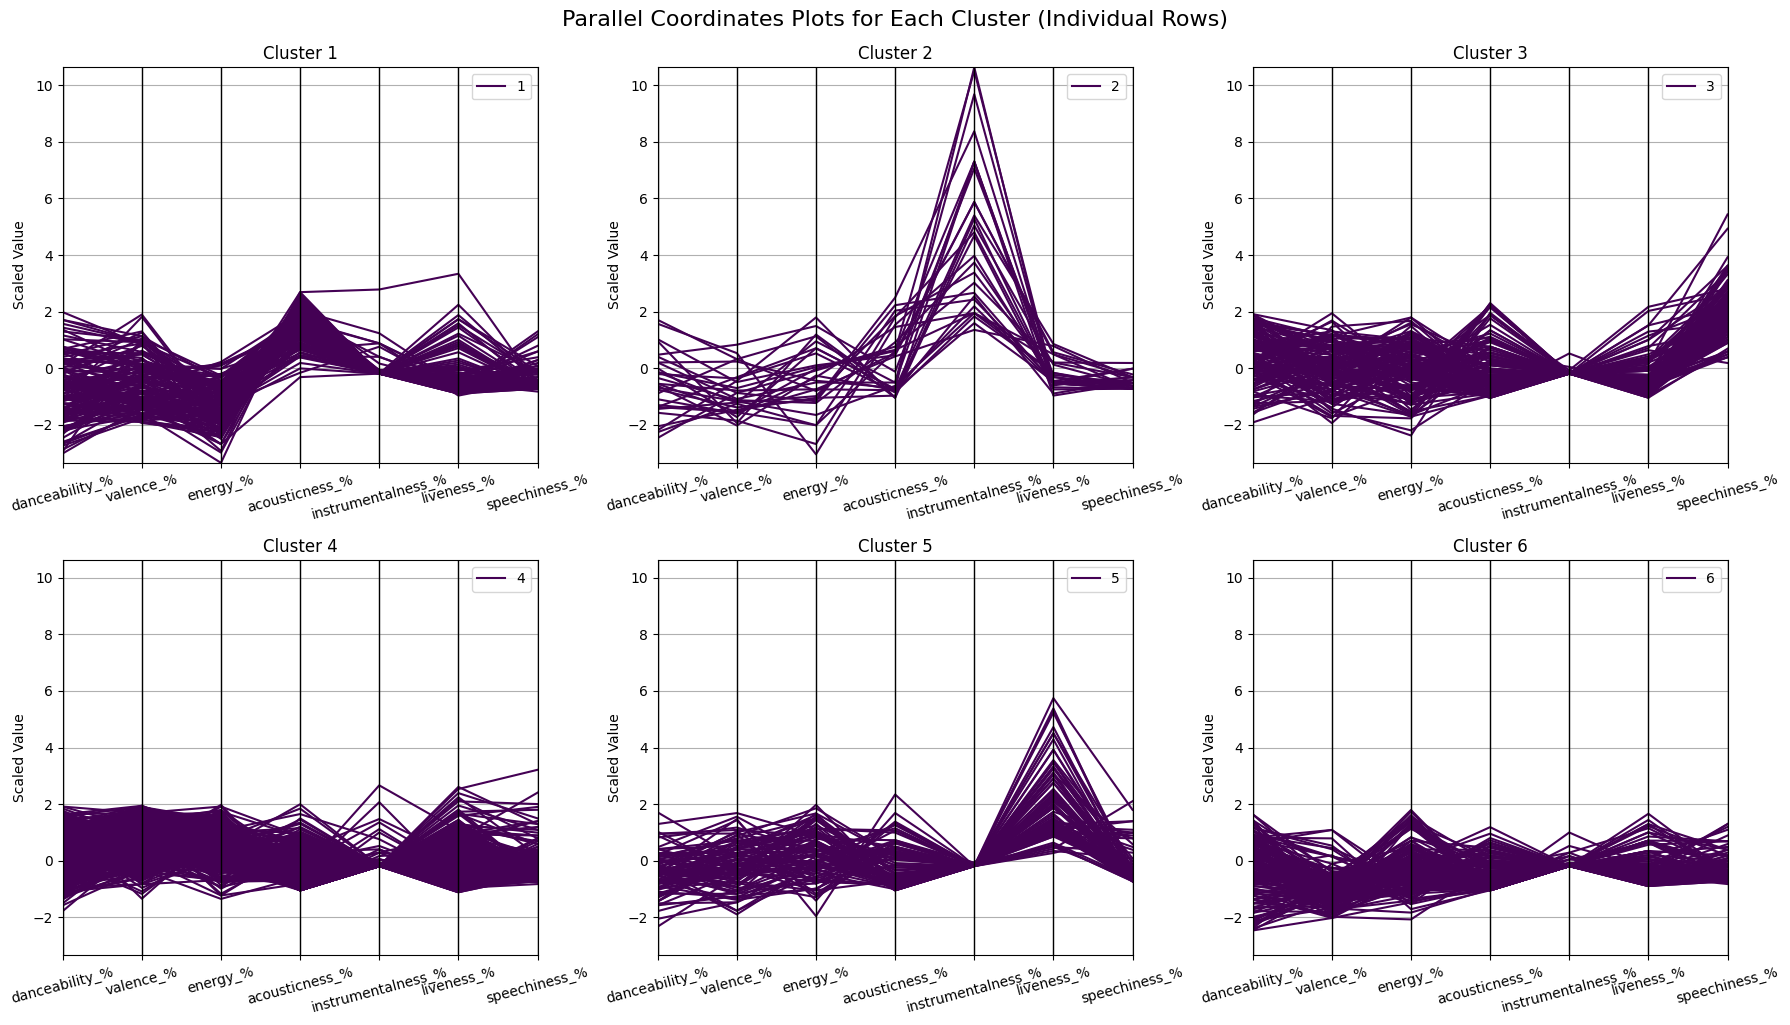

In [141]:
# To plot individual rows for each cluster, we need to select the columns for plotting,
# including the assigned 'Cluster' column.
cols_for_plotting_individual = cluster_cols + ['Cluster']
df_plot_individual = df_scaled_clustering[cols_for_plotting_individual].copy()

# We need to handle the index for the parallel coordinates plot function
# parallel_coordinates expects the 'class' column to be separate
# Let's iterate through each cluster and create a separate plot

unique_clusters = df_plot_individual['Cluster'].unique()
unique_clusters.sort() # Sort cluster numbers for order

# Determine the number of rows and columns for the subplot grid
n_clusters = len(unique_clusters)
n_cols = 3
n_rows = (n_clusters + n_cols - 1) // n_cols # Calculate number of rows needed

# Create a single figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5)) # Adjust figsize as needed
axes = axes.flatten() # Flatten the axes array for easier iteration

# Determine the global minimum and maximum values across all features and all data points for consistent y-axis
global_min = df_scaled_clustering[cluster_cols].values.min()
global_max = df_scaled_clustering[cluster_cols].values.max()

for i, cluster_id in enumerate(unique_clusters):
    # Filter the dataframe for the current cluster
    df_cluster_subset = df_plot_individual[df_plot_individual['Cluster'] == cluster_id].copy()

    # The 'class' column (Cluster) needs to be the last column for parallel_coordinates
    # and we need to ensure the data columns are in the correct order
    data_cols = cluster_cols # Ensure data columns are in the original order
    df_cluster_subset = df_cluster_subset[data_cols + ['Cluster']]

    # Plot parallel coordinates for the individual rows in this cluster on the current subplot
    parallel_coordinates(df_cluster_subset, 'Cluster', colormap=plt.get_cmap("viridis"), ax=axes[i])

    axes[i].set_title(f'Cluster {cluster_id}')
    axes[i].set_ylabel('Scaled Value')
    axes[i].tick_params(axis='x', rotation=15)
    axes[i].grid(True)
    axes[i].set_ylim(global_min, global_max) # Set the same y-axis limits for all subplots


# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout() # Adjust layout to prevent titles/labels overlapping
plt.suptitle('Parallel Coordinates Plots for Each Cluster (Individual Rows)', y=1.02, fontsize=16) # Add a main title
plt.show()

This gives us a row level view of how cohesive each attribute of each cluster is.  When the lines are close together, the more similar the songs are.  The more spread out they are, the more different.  

"Good" clusters have small variability within clusters and large variability between clusters.  



# Comment 3.c) Based on the parallel plots for the six clusters, Clusters 3 and 5 show very little or no variability in instrumentalness, indicating that the values for this factor are very similar within these clusters.

Cluster 2 shows the greatest variability across most of the factors, with the highest variation observed in instrumentalness, while speechiness shows relatively less variation compared with the other factors.

Clusters 1, 4, and 6 appear to contain more similar observations within each cluster. Also Cluster 4 is the largest cluster, with 391 songs (almost 40% of the data) and from the parallel plot they all are of similar kind songs. Although the data points are spread across the different factors, the variation is relatively limited in these cluseter (1,4,6). Since the variables were standardized, most of the values in these clusters appear to fall approximately within the −2 to +2 range, indicating moderate variation around the standardized mean.

Now let's look at cluster separation.

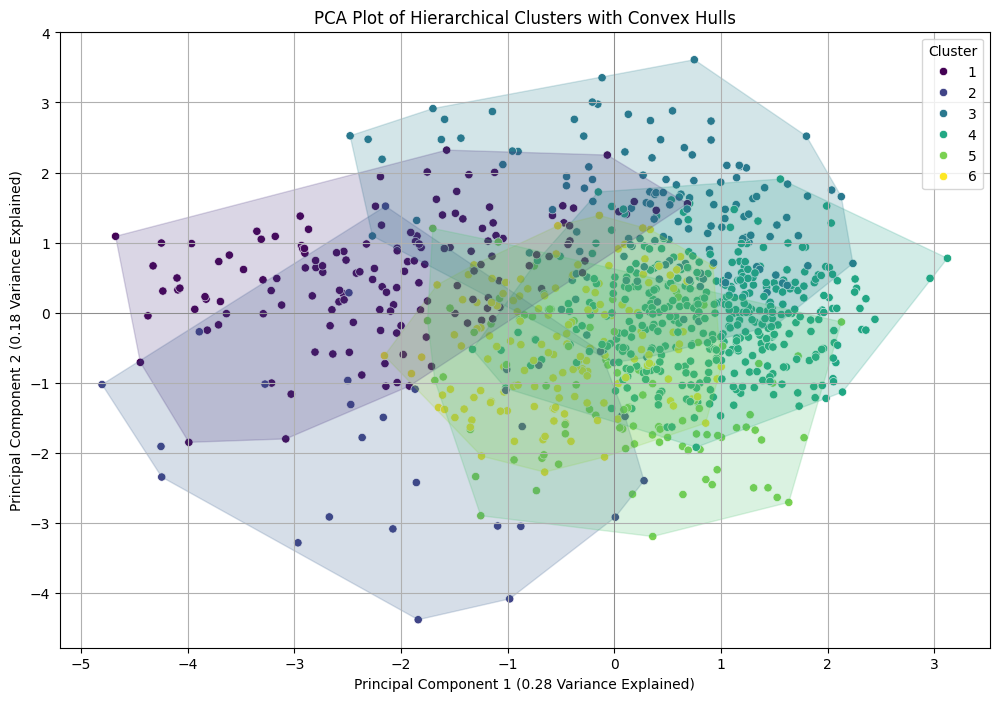

In [142]:
# Biplots using Principal Component Analysis (PCA)
# This helps visualize clusters in a reduced-dimensional space.

from sklearn.decomposition import PCA
# import matplotlib.patches as patches # Import patches for drawing ellipses - not needed for convex hull
from scipy.spatial import ConvexHull # Import ConvexHull
import matplotlib.patches as patches # Import patches for drawing polygons

# Use the scaled data used for hierarchical clustering
# This is df_scaled_clustering, excluding the 'Cluster' column which was added later
df_scaled_pca_input = df_scaled_clustering.drop(columns=['Cluster'])

# Perform PCA - let's keep 2 components for a 2D biplot
pca = PCA(n_components=2)
principal_components = pca.fit_transform(df_scaled_pca_input)

# Create a DataFrame with the principal components
df_principal_components = pd.DataFrame(data=principal_components, columns=['principal_component_1', 'principal_component_2'])

# Add the hierarchical cluster labels to the PCA dataframe
# Ensure the index aligns with the original scaled data before PCA
df_principal_components['Cluster'] = df_scaled_clustering['Cluster']

# --- Plotting the Biplot ---

plt.figure(figsize=(12, 8))
ax = plt.gca() # Get the current axes for adding patches

# Create a scatter plot of the data points in the PCA space, colored by cluster
sns.scatterplot(x='principal_component_1', y='principal_component_2', hue='Cluster', data=df_principal_components, palette='viridis', legend='full', ax=ax)

# Add Convex Hulls for each cluster
for cluster_id in df_principal_components['Cluster'].unique():
    # Filter data for the current cluster
    cluster_data = df_principal_components[df_principal_components['Cluster'] == cluster_id]

    if len(cluster_data) >= 3: # Need at least 3 points to form a polygon
        # Get the points for the convex hull
        points = cluster_data[['principal_component_1', 'principal_component_2']].values

        # Calculate the convex hull
        hull = ConvexHull(points)

        # Get the vertices of the convex hull in order
        hull_points = points[hull.vertices]

        # Add the polygon patch for the convex hull
        polygon = patches.Polygon(hull_points,
                                  color=sns.color_palette('viridis', n_colors=len(df_principal_components['Cluster'].unique()))[cluster_id - 1], # Get color based on cluster_id
                                  alpha=0.2, fill=True)

        # Add the polygon to the plot
        ax.add_patch(polygon)
    elif len(cluster_data) > 0: # Handle clusters with 1 or 2 points (cannot form a hull)
         print(f"Cluster {cluster_id} has {len(cluster_data)} points and cannot form a Convex Hull.")


plt.title('PCA Plot of Hierarchical Clusters with Convex Hulls') # Updated title
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.2f} Variance Explained)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.2f} Variance Explained)')
plt.grid(True)
plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.show()

From this we can see that we have achieve closure to good separation between clusters.  Although all cluster have some overlapping but the major overlapping is between 6 an 5.
I tried with k values (3,4,5,8, 10, 15) but the biplot with PCA still have lots of overlapping cluster. The best that I feel is with cluster count 6.

# Question 4. Perform K-means clustering danceability_%, valence_%, energy_%, acousticness_%, instrumentalness_%, liveliness_%, and speechiness_%.  For K, use the number selected in question 3a.

d. Produce the parallel plot for the cluster means.  Describe the notable attributes of each cluster and give each cluster a meaningful name.


e. Produce row level parallel plots for each cluster and the biplot of the clusters.  Describe the observable variability within the clusters and between the clusters.

In [143]:
# Get the cluster assignments for k=5
k = 6
clusters = fcluster(linked, t=k, criterion='maxclust')

# Assign the cluster labels to the dataframe
df['Cluster'] = clusters

# Print the first few rows of the dataframe to verify that the cluster labels have been assigned
print(df.head())

                            track_name    artist(s)_name  artist_count  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook             2   
1                                 LALA       Myke Towers             1   
2                              vampire    Olivia Rodrigo             1   
3                         Cruel Summer      Taylor Swift             1   
4                       WHERE SHE GOES         Bad Bunny             1   

   released_year  released_month  released_day  in_spotify_playlists  \
0           2023               7            14                   553   
1           2023               3            23                  1474   
2           2023               6            30                  1397   
3           2019               8            23                  7858   
4           2023               5            18                  3133   

   in_spotify_charts    streams  streams (M)  in_apple_playlists  \
0                147  141381703          141          

In [144]:
# Assign the cluster labels to the standardized dataframe
df_scaled_clustering['Cluster'] = clusters

# Print the first few rows of the dataframe to verify that the standardized data has the clusters added too
print(df_scaled_clustering.head())

   danceability_%  valence_%  energy_%  acousticness_%  instrumentalness_%  \
0        0.890052   1.601891  1.131483        0.150886           -0.188234   
1        0.274608   0.408787  0.587671       -0.772619           -0.188234   
2       -1.093045  -0.826928 -0.681226       -0.387825           -0.188234   
3       -0.819514   0.280954  0.466823       -0.618702           -0.188234   
4       -0.135688  -1.210426  0.950212       -0.503264            7.303165   

   liveness_%  speechiness_%  Cluster  
0   -0.744961      -0.619429        4  
1   -0.599095      -0.619429        4  
2    0.932504      -0.417616        4  
3   -0.526161       0.490540        4  
4   -0.526161      -0.417616        2  


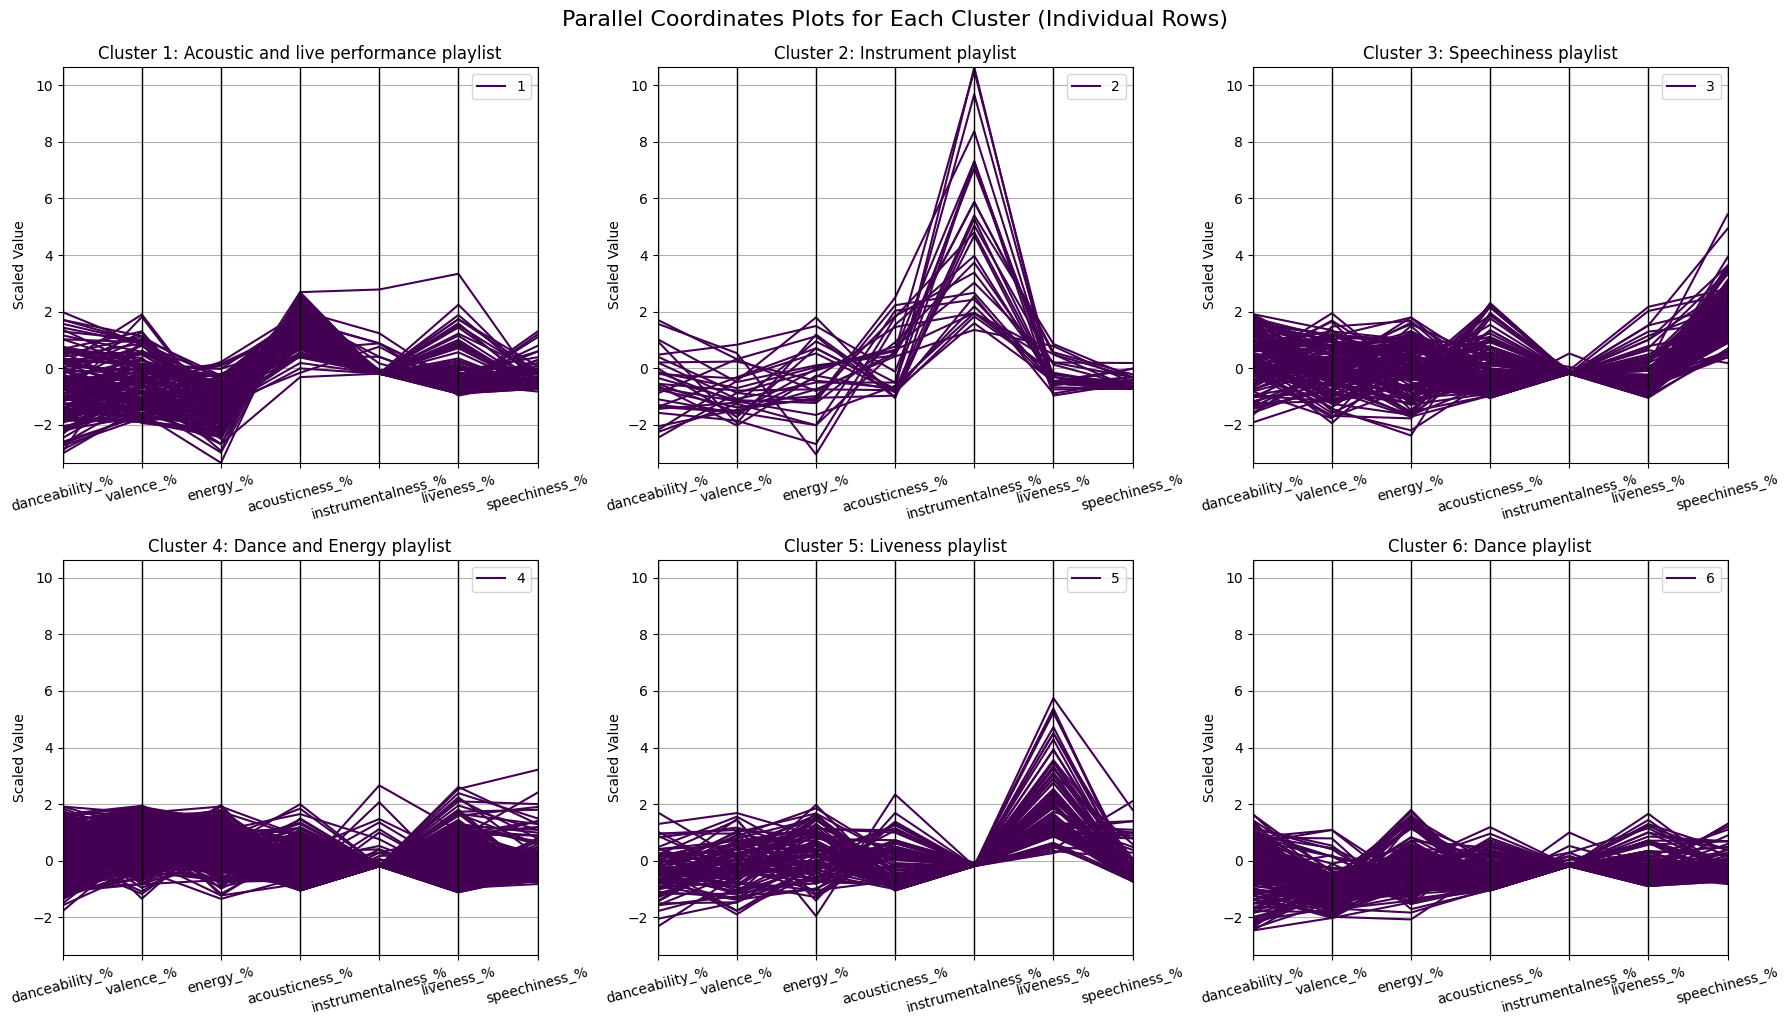

In [145]:
# To plot individual rows for each cluster, we need to select the columns for plotting,
# including the assigned 'Cluster' column.
cols_for_plotting_individual = cluster_cols + ['Cluster']
df_plot_individual = df_scaled_clustering[cols_for_plotting_individual].copy()

# We need to handle the index for the parallel coordinates plot function
# parallel_coordinates expects the 'class' column to be separate
# Let's iterate through each cluster and create a separate plot

unique_clusters = df_plot_individual['Cluster'].unique()
unique_clusters.sort() # Sort cluster numbers for order

# Determine the number of rows and columns for the subplot grid
n_clusters = len(unique_clusters)
n_cols = 3
n_rows = (n_clusters + n_cols - 1) // n_cols # Calculate number of rows needed

# Create a single figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5)) # Adjust figsize as needed
axes = axes.flatten() # Flatten the axes array for easier iteration

# Determine the global minimum and maximum values across all features and all data points for consistent y-axis
global_min = df_scaled_clustering[cluster_cols].values.min()
global_max = df_scaled_clustering[cluster_cols].values.max()

cluster_names = {
    1: 'Acoustic and live performance playlist',
    2: 'Instrument playlist',
    3: 'Speechiness playlist',
    4: 'Dance and Energy playlist',
    5: 'Liveness playlist',
    6: 'Dance playlist'
}

for i, cluster_id in enumerate(unique_clusters):
    # Filter the dataframe for the current cluster
    df_cluster_subset = df_plot_individual[df_plot_individual['Cluster'] == cluster_id].copy()

    # The 'class' column (Cluster) needs to be the last column for parallel_coordinates
    # and we need to ensure the data columns are in the correct order
    data_cols = cluster_cols # Ensure data columns are in the original order
    df_cluster_subset = df_cluster_subset[data_cols + ['Cluster']]

    # Plot parallel coordinates for the individual rows in this cluster on the current subplot
    parallel_coordinates(df_cluster_subset, 'Cluster', colormap=plt.get_cmap("viridis"), ax=axes[i])

    axes[i].set_title(
        f'Cluster {cluster_id}: {cluster_names[cluster_id]}'
    )
    axes[i].set_ylabel('Scaled Value')
    axes[i].tick_params(axis='x', rotation=15)
    axes[i].grid(True)
    axes[i].set_ylim(global_min, global_max) # Set the same y-axis limits for all subplots


# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout() # Adjust layout to prevent titles/labels overlapping
plt.suptitle('Parallel Coordinates Plots for Each Cluster (Individual Rows)', y=1.02, fontsize=16) # Add a main title
plt.show()

# Comment 4.d) Parallel plots created with meaningful cluster name. I have used the column type with the maximum variability to show the wider range, to show collection of songs playlist.

Regarding e. Produce row level parallel plots for each cluster and the biplot of the clusters.  Describe the observable variability within the clusters and between the clusters.

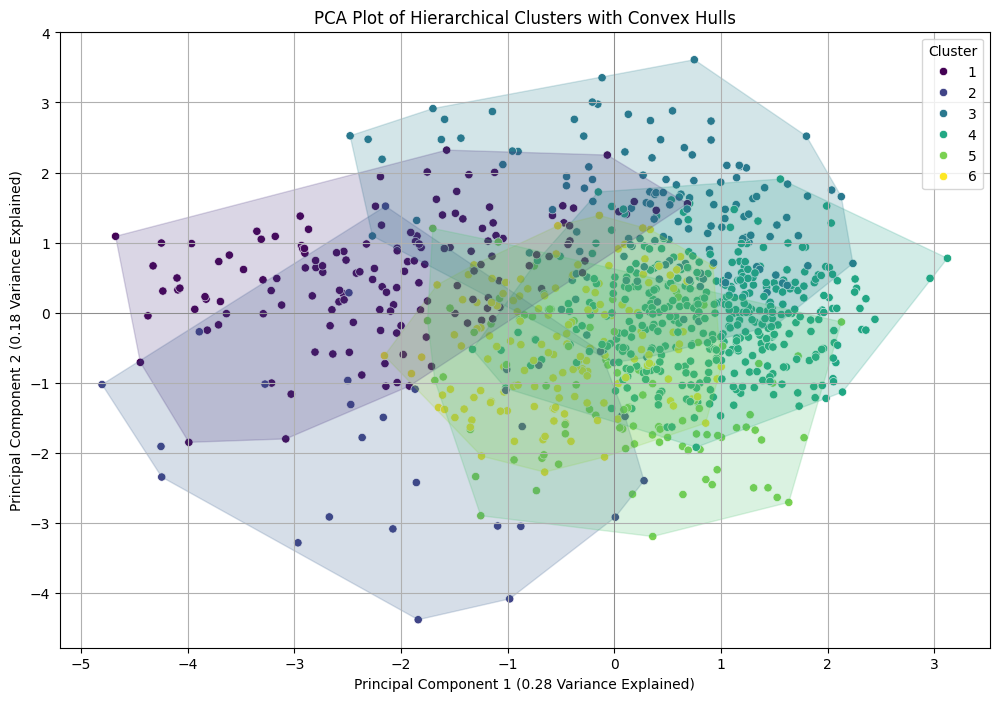

In [146]:
# Biplots using Principal Component Analysis (PCA)
# This helps visualize clusters in a reduced-dimensional space.

from sklearn.decomposition import PCA
# import matplotlib.patches as patches # Import patches for drawing ellipses - not needed for convex hull
from scipy.spatial import ConvexHull # Import ConvexHull
import matplotlib.patches as patches # Import patches for drawing polygons

# Use the scaled data used for hierarchical clustering
# This is df_scaled_clustering, excluding the 'Cluster' column which was added later
df_scaled_pca_input = df_scaled_clustering.drop(columns=['Cluster'])

# Perform PCA - let's keep 2 components for a 2D biplot
pca = PCA(n_components=2)
principal_components = pca.fit_transform(df_scaled_pca_input)

# Create a DataFrame with the principal components
df_principal_components = pd.DataFrame(data=principal_components, columns=['principal_component_1', 'principal_component_2'])

# Add the hierarchical cluster labels to the PCA dataframe
# Ensure the index aligns with the original scaled data before PCA
df_principal_components['Cluster'] = df_scaled_clustering['Cluster']

# --- Plotting the Biplot ---

plt.figure(figsize=(12, 8))
ax = plt.gca() # Get the current axes for adding patches

# Create a scatter plot of the data points in the PCA space, colored by cluster
sns.scatterplot(x='principal_component_1', y='principal_component_2', hue='Cluster', data=df_principal_components, palette='viridis', legend='full', ax=ax)

# Add Convex Hulls for each cluster
for cluster_id in df_principal_components['Cluster'].unique():
    # Filter data for the current cluster
    cluster_data = df_principal_components[df_principal_components['Cluster'] == cluster_id]

    if len(cluster_data) >= 3: # Need at least 3 points to form a polygon
        # Get the points for the convex hull
        points = cluster_data[['principal_component_1', 'principal_component_2']].values

        # Calculate the convex hull
        hull = ConvexHull(points)

        # Get the vertices of the convex hull in order
        hull_points = points[hull.vertices]

        # Add the polygon patch for the convex hull
        polygon = patches.Polygon(hull_points,
                                  color=sns.color_palette('viridis', n_colors=len(df_principal_components['Cluster'].unique()))[cluster_id - 1], # Get color based on cluster_id
                                  alpha=0.2, fill=True)

        # Add the polygon to the plot
        ax.add_patch(polygon)
    elif len(cluster_data) > 0: # Handle clusters with 1 or 2 points (cannot form a hull)
         print(f"Cluster {cluster_id} has {len(cluster_data)} points and cannot form a Convex Hull.")


plt.title('PCA Plot of Hierarchical Clusters with Convex Hulls') # Updated title
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.2f} Variance Explained)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.2f} Variance Explained)')
plt.grid(True)
plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.show()

# Comment 4.e) From the cluster visualization, we can see that we achieved relatively good separation between the clusters. Although there is some overlap among all the clusters, most of the clusters show distinguishable patterns based on the selected musical characteristics. The most noticeable overlap appears between Clusters 5 and 6, indicating that the songs in these two clusters have relatively similar characteristics.

I also experimented with different values of k, including 3, 4, 5, 8, 10, and 15, to determine an appropriate number of clusters. However, the PCA biplots for these different cluster counts continued to show considerable overlap between the clusters, making it difficult to clearly distinguish them. Among the different values tested, k = 6 provided the clearest separation and the most interpretable grouping in the PCA visualization. Therefore, I selected six clusters as the final clustering solution.

# Question 5. Which clustering technique has yielded better results?  Explain your choice.

In [147]:
# Ensure we are working with the original scaled data used for the manual steps
# This is df_scaled, which was created after standardizing cols_for_distance
# And importantly, does NOT have the manually added 'Cluster 1' or 'Cluster 2' columns.
# If the previous cells were run in order, df_scaled contains the correctly scaled data.
# Let's re-select the data just to be safe, using the columns we intended to cluster on.
cols_for_kmeans = [
    'danceability_%',
    'valence_%',
    'energy_%',
    'acousticness_%',
    'instrumentalness_%',
    'liveness_%',
    'speechiness_%'
]

df_scaled_kmeans_input = df_scaled_clustering[cols_for_kmeans].copy()

# Apply K-means clustering
# Initialize the KMeans model with k=3 (n_clusters=3)
# random_state ensures reproducibility
# n_init=10 is optional but recommended to try multiple centroid seeds
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model to the scaled data and predict the cluster assignments
df_scaled_kmeans_input['Cluster'] = kmeans.fit_predict(df_scaled_kmeans_input)

# Print the first few rows of the dataframe with the new cluster assignments
print("Head of the scaled dataframe with K-means cluster assignments (k=3):")
print(df_scaled_kmeans_input.head())

# Print the counts of each cluster
print("\nCounts for K-means clusters (k=3):")
print(df_scaled_kmeans_input['Cluster'].value_counts().sort_index())

# Calculate and print the final centroids
print("\nFinal Centroids for K-means clusters (k=3) on scaled data:")
print(kmeans.cluster_centers_)

# Optionally, add the K-means clusters back to the original (non-scaled) dataframe
# This requires aligning the indices correctly
df['KMeans_Cluster_k3'] = df_scaled_kmeans_input['Cluster']

print("\nHead of the original dataframe with K-means cluster assignments (k=3):")
print(df.head())

Head of the scaled dataframe with K-means cluster assignments (k=3):
   danceability_%  valence_%  energy_%  acousticness_%  instrumentalness_%  \
0        0.890052   1.601891  1.131483        0.150886           -0.188234   
1        0.274608   0.408787  0.587671       -0.772619           -0.188234   
2       -1.093045  -0.826928 -0.681226       -0.387825           -0.188234   
3       -0.819514   0.280954  0.466823       -0.618702           -0.188234   
4       -0.135688  -1.210426  0.950212       -0.503264            7.303165   

   liveness_%  speechiness_%  Cluster  
0   -0.744961      -0.619429        0  
1   -0.599095      -0.619429        0  
2    0.932504      -0.417616        1  
3   -0.526161       0.490540        0  
4   -0.526161      -0.417616        2  

Counts for K-means clusters (k=3):
Cluster
0    683
1    252
2     17
Name: count, dtype: int64

Final Centroids for K-means clusters (k=3) on scaled data:
[[ 0.32363895  0.28863918  0.39789428 -0.38054698 -0.14638873  0.

We now have every record assigned to its optimal cluster.  Let's explore the clusters we formed.


Mean of Scaled Variables per K-means Cluster:
         danceability_%  valence_%  energy_%  acousticness_%  \
Cluster                                                        
0              0.323067   0.286507  0.396757       -0.380558   
1             -0.845022  -0.721416 -1.052399        1.021253   
2             -0.453466  -0.816902 -0.340010        0.150886   

         instrumentalness_%  liveness_%  speechiness_%  
Cluster                                                 
0                 -0.146450    0.033812       0.117497  
1                 -0.050920   -0.071486      -0.286278  
2                  6.638662   -0.298781      -0.476973  

Number of Data Points per K-means Cluster:
Cluster
0    683
1    252
2     17
Name: count, dtype: int64


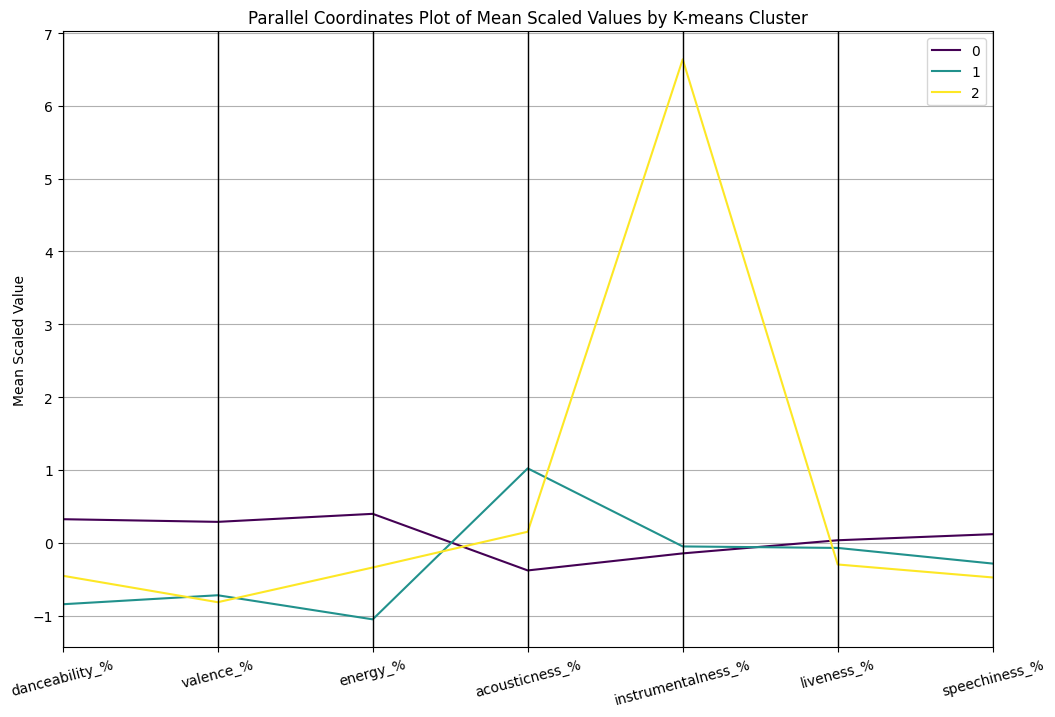

In [148]:
# Parallel Coordinates Plot for K-means clusters
# Use the dataframe with K-means cluster assignments on scaled data (df_scaled_kmeans_input)
# The cluster assignments are in the 'Cluster' column of this DataFrame.
cols_for_plotting_kmeans = cols_for_kmeans + ['Cluster'] # cols_for_kmeans is already defined

# To get a better sense of the cluster profiles, calculate the mean
# of the scaled variables for each K-means cluster.
# Group by the 'Cluster' column in df_scaled_kmeans_input
cluster_means_scaled_kmeans = df_scaled_kmeans_input.groupby('Cluster')[cols_for_kmeans].mean()

print("\nMean of Scaled Variables per K-means Cluster:")
print(cluster_means_scaled_kmeans)

# Add cluster counts for K-means clusters
cluster_counts_kmeans = df_scaled_kmeans_input['Cluster'].value_counts().sort_index()
print("\nNumber of Data Points per K-means Cluster:")
print(cluster_counts_kmeans)

# We can visualize these means on a parallel coordinates plot
plt.figure(figsize=(12, 8))
# Use cluster_means_scaled_kmeans and the 'Cluster' column after resetting the index
parallel_coordinates(cluster_means_scaled_kmeans.reset_index(), 'Cluster', colormap=plt.get_cmap("viridis"))

plt.title('Parallel Coordinates Plot of Mean Scaled Values by K-means Cluster')
plt.ylabel('Mean Scaled Value')
plt.xticks(rotation=15)
plt.grid(True)
plt.show()

Cluster 0 has above-average danceability, valence, and energy, with relatively low acousticness and instrumentalness. This group can therefore be characterized as generally more energetic and dance-oriented songs.

Cluster 1 has below-average danceability, valence, and energy, while acousticness is relatively high. This suggests that these songs are generally less energetic and less dance-oriented, with stronger acoustic characteristics.

Cluster 2 is particularly distinct because of its extremely high instrumentalness, with a standardized mean of approximately 6.64. It also has below-average danceability, valence, energy, liveness, and speechiness. Although this cluster contains only 17 songs, its very high instrumentalness clearly separates it from the other two groups.

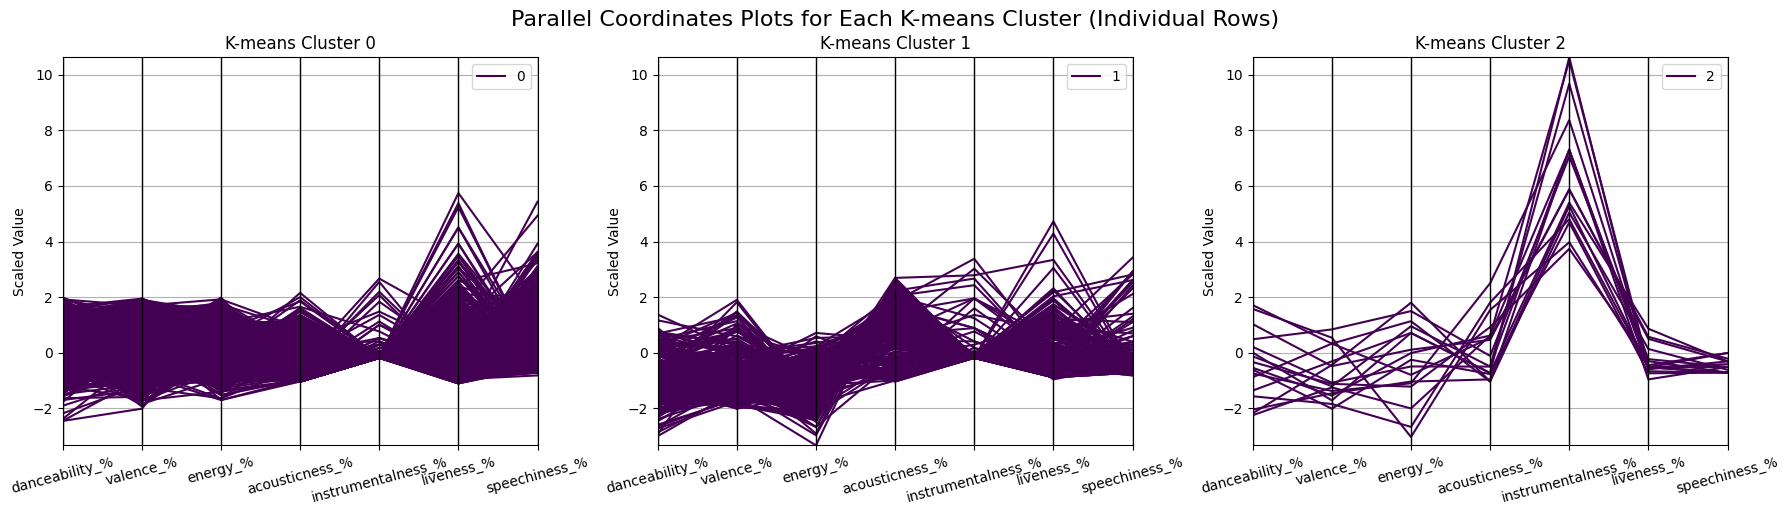

In [149]:
# To plot individual rows for each cluster, we need to select the columns for plotting,
# including the assigned 'Cluster' column from the K-means results.
cols_for_plotting_individual_kmeans = cols_for_kmeans + ['Cluster']
# Use the dataframe with K-means cluster assignments on scaled data (df_scaled_kmeans_input)
df_plot_individual_kmeans = df_scaled_kmeans_input[cols_for_plotting_individual_kmeans].copy()

# We need to handle the index for the parallel coordinates plot function
# parallel_coordinates expects the 'class' column to be separate
# Let's iterate through each K-means cluster and create a separate plot

unique_clusters_kmeans = df_plot_individual_kmeans['Cluster'].unique()
unique_clusters_kmeans.sort() # Sort cluster numbers for order

# Determine the number of rows and columns for the subplot grid
n_clusters_kmeans = len(unique_clusters_kmeans)
n_cols_kmeans = 3 # Keep 3 columns as before
n_rows_kmeans = (n_clusters_kmeans + n_cols_kmeans - 1) // n_cols_kmeans # Calculate number of rows needed

# Create a single figure with subplots
fig_kmeans, axes_kmeans = plt.subplots(n_rows_kmeans, n_cols_kmeans, figsize=(n_cols_kmeans * 6, n_rows_kmeans * 5)) # Adjust figsize as needed
axes_kmeans = axes_kmeans.flatten() # Flatten the axes array for easier iteration

# Determine the global minimum and maximum values across all features and all data points for consistent y-axis
# Use the scaled data that was input to K-means for consistent scaling
global_min_kmeans = df_scaled_kmeans_input[cols_for_kmeans].values.min()
global_max_kmeans = df_scaled_kmeans_input[cols_for_kmeans].values.max()

for i, cluster_id_kmeans in enumerate(unique_clusters_kmeans):
    # Filter the dataframe for the current K-means cluster
    df_cluster_subset_kmeans = df_plot_individual_kmeans[df_plot_individual_kmeans['Cluster'] == cluster_id_kmeans].copy()

    # The 'class' column (Cluster) needs to be the last column for parallel_coordinates
    # and we need to ensure the data columns are in the correct order
    data_cols_kmeans = cols_for_kmeans # Ensure data columns are in the original order
    df_cluster_subset_kmeans = df_cluster_subset_kmeans[data_cols_kmeans + ['Cluster']]

    # Plot parallel coordinates for the individual rows in this K-means cluster on the current subplot
    # Use a colormap suitable for categorical data if needed, or keep viridis
    parallel_coordinates(df_cluster_subset_kmeans, 'Cluster', colormap=plt.get_cmap("viridis"), ax=axes_kmeans[i])

    axes_kmeans[i].set_title(f'K-means Cluster {cluster_id_kmeans}')
    axes_kmeans[i].set_ylabel('Scaled Value')
    axes_kmeans[i].tick_params(axis='x', rotation=15)
    axes_kmeans[i].grid(True)
    axes_kmeans[i].set_ylim(global_min_kmeans, global_max_kmeans) # Set the same y-axis limits for all subplots


# Hide any unused subplots
for j in range(i + 1, len(axes_kmeans)):
    fig_kmeans.delaxes(axes_kmeans[j])

plt.tight_layout() # Adjust layout to prevent titles/labels overlapping
plt.suptitle('Parallel Coordinates Plots for Each K-means Cluster (Individual Rows)', y=1.02, fontsize=16) # Add a main title
plt.show()

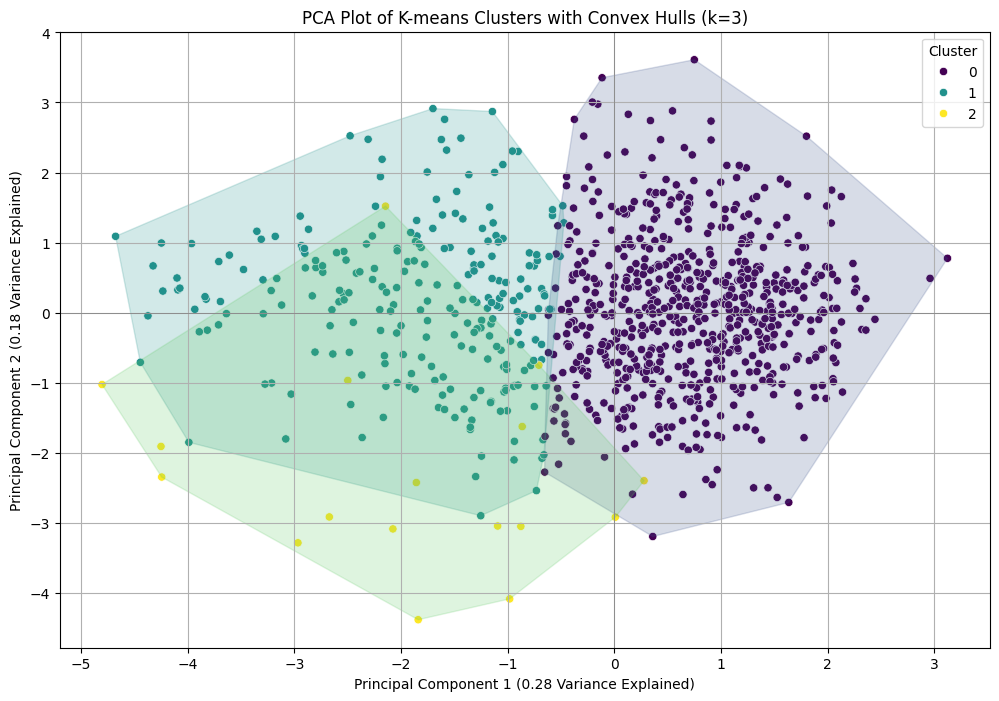

In [150]:
# Biplots using Principal Component Analysis (PCA) for K-means clusters
# This helps visualize K-means clusters in a reduced-dimensional space.

from sklearn.decomposition import PCA
import matplotlib.patches as patches # Import patches for drawing polygons
from scipy.spatial import ConvexHull # Import ConvexHull


# Use the scaled data that was input to K-means clustering
# This is df_scaled_kmeans_input, which already has the 'Cluster' column from K-means results
# We need to drop the 'Cluster' column before performing PCA
df_scaled_kmeans_pca_input = df_scaled_kmeans_input.drop(columns=['Cluster'])


# Perform PCA - let's keep 2 components for a 2D biplot
pca_kmeans = PCA(n_components=2)
principal_components_kmeans = pca_kmeans.fit_transform(df_scaled_kmeans_pca_input)

# Create a DataFrame with the principal components
df_principal_components_kmeans = pd.DataFrame(data=principal_components_kmeans, columns=['principal_component_1', 'principal_component_2'])

# Add the K-means cluster labels to the PCA dataframe
# Ensure the index aligns with the original scaled data before PCA
df_principal_components_kmeans['Cluster'] = df_scaled_kmeans_input['Cluster']


# --- Plotting the Biplot ---

plt.figure(figsize=(12, 8))
ax_kmeans = plt.gca() # Get the current axes for adding patches

# Create a scatter plot of the data points in the PCA space, colored by K-means cluster
sns.scatterplot(x='principal_component_1', y='principal_component_2', hue='Cluster', data=df_principal_components_kmeans, palette='viridis', legend='full', ax=ax_kmeans)

# Add Convex Hulls for each K-means cluster
for cluster_id_kmeans in df_principal_components_kmeans['Cluster'].unique():
    # Filter data for the current K-means cluster
    cluster_data_kmeans = df_principal_components_kmeans[df_principal_components_kmeans['Cluster'] == cluster_id_kmeans]

    if len(cluster_data_kmeans) >= 3: # Need at least 3 points to form a polygon
        # Get the points for the convex hull
        points_kmeans = cluster_data_kmeans[['principal_component_1', 'principal_component_2']].values

        # Calculate the convex hull
        hull_kmeans = ConvexHull(points_kmeans)

        # Get the vertices of the convex hull in order
        hull_points_kmeans = points_kmeans[hull_kmeans.vertices]

        # Add the polygon patch for the convex hull
        polygon_kmeans = patches.Polygon(hull_points_kmeans,
                                  color=sns.color_palette('viridis', n_colors=len(df_principal_components_kmeans['Cluster'].unique()))[cluster_id_kmeans], # Get color based on cluster_id
                                  alpha=0.2, fill=True)

        # Add the polygon to the plot
        ax_kmeans.add_patch(polygon_kmeans)
    elif len(cluster_data_kmeans) > 0: # Handle clusters with 1 or 2 points (cannot form a hull)
         print(f"K-means Cluster {cluster_id_kmeans} has {len(cluster_data_kmeans)} points and cannot form a Convex Hull.")


plt.title('PCA Plot of K-means Clusters with Convex Hulls (k=3)') # Updated title
plt.xlabel(f'Principal Component 1 ({pca_kmeans.explained_variance_ratio_[0]:.2f} Variance Explained)')
plt.ylabel(f'Principal Component 2 ({pca_kmeans.explained_variance_ratio_[1]:.2f} Variance Explained)')
plt.grid(True)
plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.show()

#Comment 5: The ward clustering technique has yielded better result.

Compared with the K-means solution, the Ward hierarchical clustering with six clusters provided a more detailed and interpretable segmentation of the songs. Instead of concentrating most observations into two large groups and one very small group, the six-cluster solution allowed more variation in musical characteristics to be represented across the groups.

Therefore, based on the PCA visualization, parallel plots, cluster profiles, and interpretability of the resulting groups, I selected the Ward hierarchical clustering solution with six clusters as the preferred clustering approach for this analysis. Although there is still some overlap between clusters, the six-cluster solution provides a useful way to understand different musical patterns in the dataset.

# Question 6. Save the cluster assignments back to the dataset for the chosen technique.


In [151]:
# Assign the cluster labels to the standardized dataframe
df_scaled_clustering['Cluster'] = clusters

# Print the first few rows of the dataframe to verify that the standardized data has the clusters added too
print(df_scaled_clustering.head())

   danceability_%  valence_%  energy_%  acousticness_%  instrumentalness_%  \
0        0.890052   1.601891  1.131483        0.150886           -0.188234   
1        0.274608   0.408787  0.587671       -0.772619           -0.188234   
2       -1.093045  -0.826928 -0.681226       -0.387825           -0.188234   
3       -0.819514   0.280954  0.466823       -0.618702           -0.188234   
4       -0.135688  -1.210426  0.950212       -0.503264            7.303165   

   liveness_%  speechiness_%  Cluster  
0   -0.744961      -0.619429        4  
1   -0.599095      -0.619429        4  
2    0.932504      -0.417616        4  
3   -0.526161       0.490540        4  
4   -0.526161      -0.417616        2  



Mean of Scaled Variables per Cluster:
         danceability_%  valence_%  energy_%  acousticness_%  \
Cluster                                                        
1             -0.758109  -0.501405 -1.310536        1.612318   
2             -0.529477  -0.904803 -0.418695        0.282247   
3              0.412849   0.020078 -0.058297       -0.019088   
4              0.365552   0.675786  0.560781       -0.370505   
5             -0.426502  -0.133448  0.274928       -0.165829   
6             -0.223923  -0.999571 -0.202515       -0.532806   

         instrumentalness_%  liveness_%  speechiness_%  
Cluster                                                 
1                 -0.114623   -0.256259      -0.461548  
2                  4.818333   -0.236943      -0.490686  
3                 -0.179680   -0.344091       1.996148  
4                 -0.143833   -0.104417      -0.308968  
5                 -0.184314    2.001657      -0.256831  
6                 -0.160616   -0.315831      -0.3

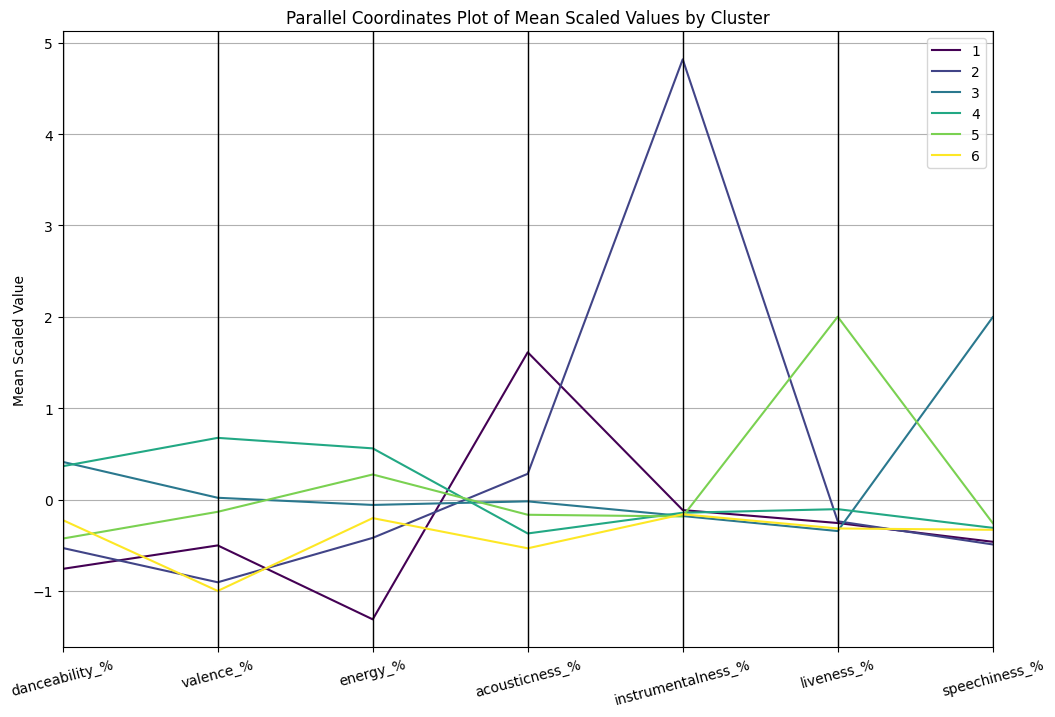

In [152]:
# Parallel Coordinates Plot
# The parallel coordinates plot is useful for visualizing the values of each variable
# for records belonging to different clusters. It helps see the profile of each cluster.
# It's best used with scaled data.

# Select the columns to plot (all numeric columns except 'Cluster')
cols_for_plotting = cluster_cols + ['Cluster'] # Include the Cluster column for coloring
df_plot = df_scaled_clustering[cols_for_plotting]

# To get a better sense of the cluster profiles, we can calculate the mean
# of the scaled variables for each cluster.
cluster_means_scaled = df_scaled_clustering.groupby('Cluster')[cluster_cols].mean()

print("\nMean of Scaled Variables per Cluster:")
print(cluster_means_scaled)

# Add cluster counts
cluster_counts = df_scaled_clustering['Cluster'].value_counts().sort_index()
print("\nNumber of Data Points per Cluster:")
print(cluster_counts)

# We can visualize these means on a parallel coordinates plot
plt.figure(figsize=(12, 8))
parallel_coordinates(cluster_means_scaled.reset_index(), 'Cluster', colormap=plt.get_cmap("viridis")) # Use reset_index() to make Cluster a column again

plt.title('Parallel Coordinates Plot of Mean Scaled Values by Cluster')
plt.ylabel('Mean Scaled Value')
plt.xticks(rotation=15)
plt.grid(True)
plt.show()

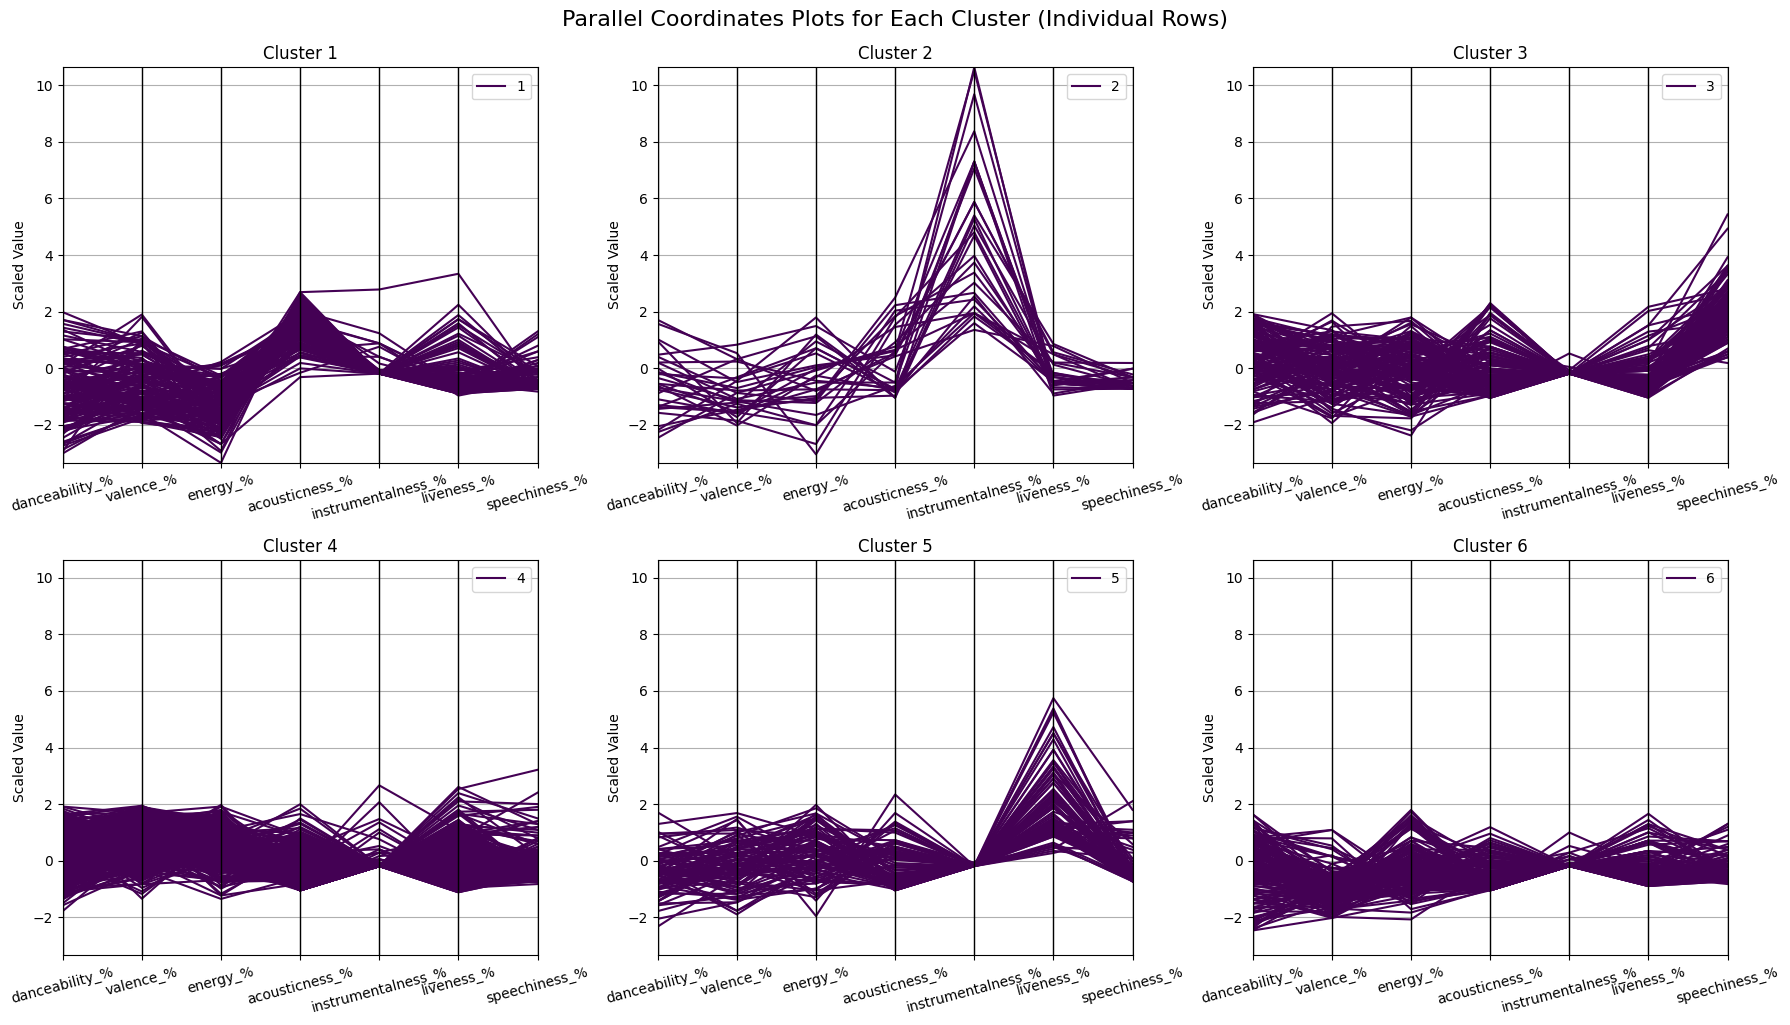

In [153]:
# To plot individual rows for each cluster, we need to select the columns for plotting,
# including the assigned 'Cluster' column.
cols_for_plotting_individual = cluster_cols + ['Cluster']
df_plot_individual = df_scaled_clustering[cols_for_plotting_individual].copy()

# We need to handle the index for the parallel coordinates plot function
# parallel_coordinates expects the 'class' column to be separate
# Let's iterate through each cluster and create a separate plot

unique_clusters = df_plot_individual['Cluster'].unique()
unique_clusters.sort() # Sort cluster numbers for order

# Determine the number of rows and columns for the subplot grid
n_clusters = len(unique_clusters)
n_cols = 3
n_rows = (n_clusters + n_cols - 1) // n_cols # Calculate number of rows needed

# Create a single figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5)) # Adjust figsize as needed
axes = axes.flatten() # Flatten the axes array for easier iteration

# Determine the global minimum and maximum values across all features and all data points for consistent y-axis
global_min = df_scaled_clustering[cluster_cols].values.min()
global_max = df_scaled_clustering[cluster_cols].values.max()

for i, cluster_id in enumerate(unique_clusters):
    # Filter the dataframe for the current cluster
    df_cluster_subset = df_plot_individual[df_plot_individual['Cluster'] == cluster_id].copy()

    # The 'class' column (Cluster) needs to be the last column for parallel_coordinates
    # and we need to ensure the data columns are in the correct order
    data_cols = cluster_cols # Ensure data columns are in the original order
    df_cluster_subset = df_cluster_subset[data_cols + ['Cluster']]

    # Plot parallel coordinates for the individual rows in this cluster on the current subplot
    parallel_coordinates(df_cluster_subset, 'Cluster', colormap=plt.get_cmap("viridis"), ax=axes[i])

    axes[i].set_title(f'Cluster {cluster_id}')
    axes[i].set_ylabel('Scaled Value')
    axes[i].tick_params(axis='x', rotation=15)
    axes[i].grid(True)
    axes[i].set_ylim(global_min, global_max) # Set the same y-axis limits for all subplots


# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout() # Adjust layout to prevent titles/labels overlapping
plt.suptitle('Parallel Coordinates Plots for Each Cluster (Individual Rows)', y=1.02, fontsize=16) # Add a main title
plt.show()

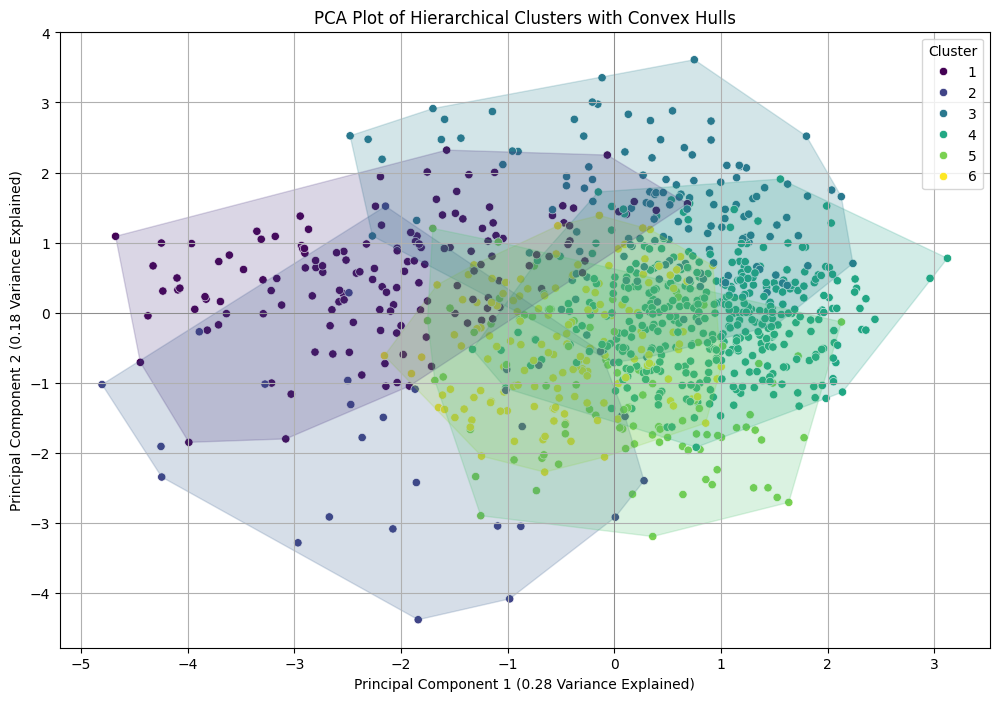

In [154]:
# Biplots using Principal Component Analysis (PCA)
# This helps visualize clusters in a reduced-dimensional space.

from sklearn.decomposition import PCA
# import matplotlib.patches as patches # Import patches for drawing ellipses - not needed for convex hull
from scipy.spatial import ConvexHull # Import ConvexHull
import matplotlib.patches as patches # Import patches for drawing polygons

# Use the scaled data used for hierarchical clustering
# This is df_scaled_clustering, excluding the 'Cluster' column which was added later
df_scaled_pca_input = df_scaled_clustering.drop(columns=['Cluster'])

# Perform PCA - let's keep 2 components for a 2D biplot
pca = PCA(n_components=2)
principal_components = pca.fit_transform(df_scaled_pca_input)

# Create a DataFrame with the principal components
df_principal_components = pd.DataFrame(data=principal_components, columns=['principal_component_1', 'principal_component_2'])

# Add the hierarchical cluster labels to the PCA dataframe
# Ensure the index aligns with the original scaled data before PCA
df_principal_components['Cluster'] = df_scaled_clustering['Cluster']

# --- Plotting the Biplot ---

plt.figure(figsize=(12, 8))
ax = plt.gca() # Get the current axes for adding patches

# Create a scatter plot of the data points in the PCA space, colored by cluster
sns.scatterplot(x='principal_component_1', y='principal_component_2', hue='Cluster', data=df_principal_components, palette='viridis', legend='full', ax=ax)

# Add Convex Hulls for each cluster
for cluster_id in df_principal_components['Cluster'].unique():
    # Filter data for the current cluster
    cluster_data = df_principal_components[df_principal_components['Cluster'] == cluster_id]

    if len(cluster_data) >= 3: # Need at least 3 points to form a polygon
        # Get the points for the convex hull
        points = cluster_data[['principal_component_1', 'principal_component_2']].values

        # Calculate the convex hull
        hull = ConvexHull(points)

        # Get the vertices of the convex hull in order
        hull_points = points[hull.vertices]

        # Add the polygon patch for the convex hull
        polygon = patches.Polygon(hull_points,
                                  color=sns.color_palette('viridis', n_colors=len(df_principal_components['Cluster'].unique()))[cluster_id - 1], # Get color based on cluster_id
                                  alpha=0.2, fill=True)

        # Add the polygon to the plot
        ax.add_patch(polygon)
    elif len(cluster_data) > 0: # Handle clusters with 1 or 2 points (cannot form a hull)
         print(f"Cluster {cluster_id} has {len(cluster_data)} points and cannot form a Convex Hull.")


plt.title('PCA Plot of Hierarchical Clusters with Convex Hulls') # Updated title
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.2f} Variance Explained)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.2f} Variance Explained)')
plt.grid(True)
plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.show()

# Comment 6: Back to the dataset for the chosen technique.

# Question 7. Make box plots showing the distribution of streams (M) by cluster.  Pretend you are a data scientist doing consulting work for a music producer.  If the producer’s biggest motivation is to generate revenue from streaming platforms, what cluster should you recommend?  What song attributes go along with that cluster?

               mean  median  count
Cluster                           
1        661.108844   362.0    147
2        388.586207   282.0     29
3        361.568345   195.0    139
4        530.938619   303.0    391
5        505.263736   263.0     91
6        494.819355   311.0    155


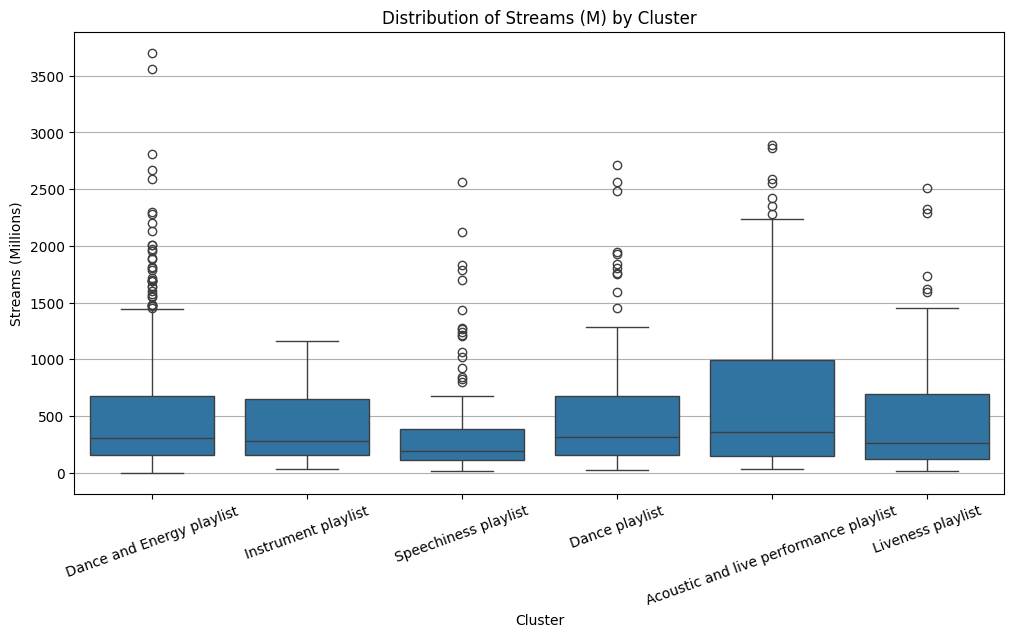

In [155]:
cluster_names = {
    1: 'Acoustic and live performance playlist',
    2: 'Instrument playlist',
    3: 'Speechiness playlist',
    4: 'Dance and Energy playlist',
    5: 'Liveness playlist',
    6: 'Dance playlist'
}

df['Cluster_Name'] = df['Cluster'].map(cluster_names)

print(
    df.groupby('Cluster')['streams (M)']
      .agg(['mean', 'median', 'count'])
)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Cluster_Name', y='streams (M)')

plt.title('Distribution of Streams (M) by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Streams (Millions)')
plt.xticks(rotation=20)
plt.grid(axis='y')
plt.show()

# Comment 7: If the music producer's primary goal is to generate revenue from streaming platforms, I would recommend focusing on Cluster 1 ('Acoustic and live performance playlist').

Cluster 1 has the highest average number of streams, at approximately 661 million, and also has the highest median number of streams, at 362 million. The fact that both the mean and median are highest suggests that this cluster has stronger streaming performance overall rather than the result being driven only by a few extremely popular songs.

However, this analysis shows an association rather than causation. Therefore, these attributes should be considered as characteristics associated with higher streaming performance rather than factors that necessarily cause higher streams.